# Particles in floor coordinates

Bmad describes each particle in the local coordinate system of the element it is in: `x` and `y` are offsets from the reference orbit, which curves through every bend. That is the natural frame for beam dynamics, but not for questions about the machine itself. Where is the beam relative to the chamber wall? How far does a chicane move it sideways? Where would a screen need to go?

Those questions are about global *floor* coordinates. This notebook converts tracked particles to floor coordinates with a `FloorTable` and draws them on top of Tao's floor plan.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np

from pytao import Tao
from pytao.model import FloorTable

## A chicane with a large energy spread

A four-bend chicane is a good test case: the reference orbit moves well away from the incoming axis, and particles of different energies take visibly different paths through it.

In [2]:
lattice = """
parameter[geometry] = open
parameter[particle] = electron
parameter[e_tot] = 50e6
beginning[beta_a] = 8
beginning[beta_b] = 8

d1: drift, L = 0.5
d2: drift, L = 1.0
d3: drift, L = 0.5
d4: drift, L = 1.0
d5: drift, L = 0.5
b1: sbend, L = 0.5, angle = -0.5, e2 = -0.5
b2: sbend, L = 0.5, angle = 0.5, e1 = 0.5
b3: sbend, L = 0.5, angle = 0.5, e2 = 0.5
b4: sbend, L = 0.5, angle = -0.5, e1 = -0.5
chicane: line = (d1, b1, d2, b2, d3, b3, d4, b4, d5)
use, chicane
"""

tao = Tao.from_contents(lattice, plot="mpl")

Track a beam with a 2% energy spread, saving the particles at every element and beam statistics every 2 cm along the line:

In [3]:
conf = tao.get_config()
conf.beam_init.n_particle = 500
conf.beam_init.random_engine = "quasi"
conf.beam_init.a_norm_emit = 1e-6
conf.beam_init.b_norm_emit = 1e-6
conf.beam_init.bunch_charge = 1e-12
conf.beam_init.sig_z = 1e-3
conf.beam_init.sig_pz = 2e-2
conf.beam.saved_at = "*"
conf.beam.comb_ds_save = 0.02
conf.set(tao)

tao.track_beam()

<!-- lume-impact detected Jupyter and will use HTML for rendering. -->

  0%|          | 0/10 [00:00<?, ?ele/s]

['', 'Tao:  set global track_type = single']

## One element

`extras=True` adds each particle's element index, its location in the element, and its `s` position. `Element.particles_to_floor` returns a new `ParticleGroup` in floor coordinates.

At the exit of the second bend the beam is centered on the reference orbit, so its mean local `x` is nearly zero. In floor coordinates it is about 0.7 m off the incoming axis:

In [4]:
P = tao.particles("b2", extras=True)
P_floor = tao.ele("b2").particles_to_floor(P)

P["mean_x"], P_floor["mean_x"], P_floor["mean_z"]

(np.float64(0.0004979793458602513),
 np.float64(0.7247583941693176),
 np.float64(2.3364336390987783))

## The whole beamline

A `FloorTable` holds the floor geometry of every element. It converts particles from any number of elements in one call, finding each particle's element from its `ix_ele` record.

In [5]:
table = tao.floor_table()
table

<FloorTable which=model with 11 elements (4 bends) in branch 0>

Collect the saved particles from every element into one `ParticleGroup` and convert them all at once:

In [6]:
groups = [tao.particles(f"0>>{ix_ele}", extras=True) for ix_ele in table.ix_ele]
P_all = sum(groups[1:], start=groups[0])
P_all_floor = table.particles_to_floor(P_all)

Tao's floor plan is drawn in the same coordinates, with Z horizontal and X vertical, so the particles can be drawn directly on top of it. Tao was started with `plot="mpl"`, so `tao.plot` draws with Matplotlib and the particles can be added with `pyplot`.

Colored by momentum, the bunches show the chicane's dispersion: at the entrance and exit the beam is a single dot, while in the middle the low-momentum particles have been bent further out than the high-momentum ones.

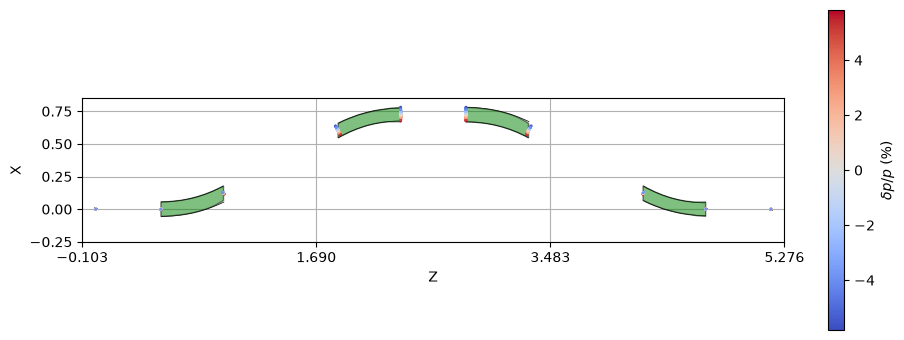

In [7]:
delta = P_all.p / P_all.p.mean() - 1

tao.plot("floor_plan", include_layout=False, figsize=(10, 3.5), ylim=(-0.25, 0.85))
points = plt.scatter(P_all_floor.z, P_all_floor.x, c=100 * delta, s=1, cmap="coolwarm", zorder=5)
plt.colorbar(points, label=r"$\delta p / p$ (%)");

## The beam envelope

Saved bunches sit at element ends, but Tao also recorded the beam's centroid and size every 2 cm along the line. `plot_floor_beam` converts those to floor coordinates and draws the centroid and the full extent of the beam on the floor plan, following the arc through each bend. Pass `extent="sigma"` for a $\pm 3\sigma$ band instead.

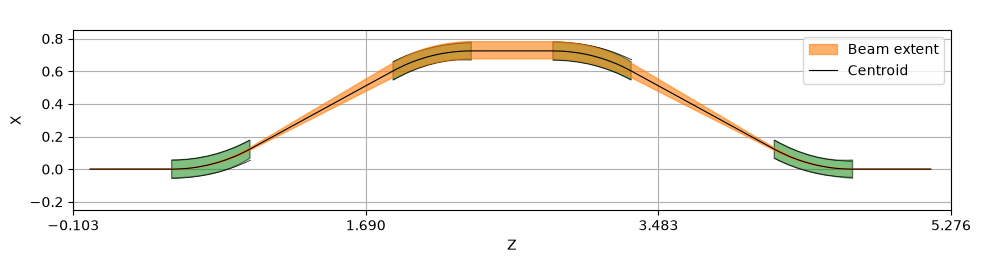

In [8]:
tao.plot_floor_beam(figsize=(10, 3.5), ylim=(-0.25, 0.85))

The envelope is narrow in the outer drifts and widest between the two middle bends, where the dispersion is largest.

A real beam is usually far smaller than the machine, and would be an invisible line at this scale. `magnification` scales the beam's offsets from the reference orbit so that it can be seen; the floor plan itself is unchanged. `FloorTable.particles_to_floor` takes the same argument.

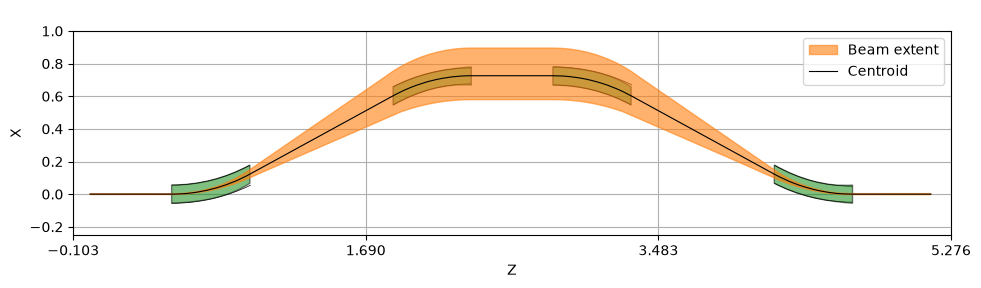

In [9]:
tao.plot_floor_beam(magnification=3, figsize=(10, 3.5), ylim=(-0.25, 1.0))

## Points along the beamline

Underneath, the envelope uses `FloorTable.points_to_floor`, which converts any local offset known as a function of `s`. The point is placed inside whichever element contains that `s`. With no offsets it gives the reference orbit itself, here at the start, the middle and the end of the chicane:

In [10]:
table.points_to_floor([0.0, 2.75, 5.5])

array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 7.24260415e-01,  0.00000000e+00,  2.58643364e+00],
       [-5.55111512e-17,  0.00000000e+00,  5.17286728e+00]])

## Without Tao

A `FloorTable` is a small file: a handful of numbers per element. Save it alongside the particles and the conversion can be repeated later with no Tao running.

In [11]:
table.write("floor_table.json")
offline_table = FloorTable.from_file("floor_table.json")

P_offline = offline_table.particles_to_floor(P_all)
np.allclose(P_offline.x, P_all_floor.x) and np.allclose(P_offline.z, P_all_floor.z)

True

In [12]:
os.remove("floor_table.json")

## Limits

- Particles inside patch-like elements (`patch`, `floor_shift`, `fiducial`, mirrors and crystals) cannot be converted; their upstream and downstream ends can.
- Reversed elements (orientation -1) are not supported; particles or points in one raise an error.
- Particles from several branches need an `ix_branch` record, which `extras=True` provides.